# Shut the Box con aprendizaje por refuerzo básico

Este cuadernillo implementa el punto 2 del examen: un agente que aprende a jugar
**Shut the Box** usando únicamente las técnicas del cuadernillo de bandits
(`02_bandits.ipynb`): valores acción-estado, exploración ε-greedy, UCB y
actualización incremental. Se usa la idea de **búsqueda asociativa** presentada
al final de ese cuadernillo: cada estado se trata como un bandit independiente.
No se usa `02_mdp.ipynb` ni iteración de valores.

## Reglas
- Hay casillas del 1 al 9, todas abiertas al inicio.
- En cada turno se tiran dos dados. Si las casillas 7, 8 y 9 están cerradas,
  el jugador puede elegir tirar un solo dado.
- Se debe cerrar un subconjunto no vacío de casillas abiertas cuya suma sea
  el total de los dados.
- Si no existe ninguna combinación válida, la partida termina.
- Si se cierran las nueve casillas, se gana.

Se reportan dos métricas: tasa de victoria y suma de casillas restantes.

In [1]:
import pickle
from functools import lru_cache
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

SEMILLA = 67
np.random.seed(SEMILLA)

## 1. Representación del estado

El tablero se representa con una máscara de 9 bits: el bit `i` vale 1 si la
casilla `i+1` sigue abierta. El estado completo es `(mascara, total)`, donde
`total = 0` indica que el agente debe elegir cuántos dados tirar.

In [2]:
NUMEROS = tuple(range(1, 10))
MASCARA_COMPLETA = (1 << 9) - 1
MASCARA_789 = (1 << 6) | (1 << 7) | (1 << 8)


def abiertas(mascara):
    return [n for n in NUMEROS if mascara & (1 << (n - 1))]


def suma_restante(mascara):
    return sum(abiertas(mascara))


def dibujar_tablero(mascara):
    partes = []
    for n in NUMEROS:
        if mascara & (1 << (n - 1)):
            partes.append(f"[{n}]")
        else:
            partes.append(" X ")
    print(" ".join(partes))

## 2. Dados y acciones válidas

Las acciones dependen de la fase del turno:
- antes de tirar: `1` o `2` dados;
- después de tirar: la máscara del subconjunto de casillas que se cierra.

In [3]:
def distribucion_dados(n_dados):
    if n_dados == 1:
        return {cara: 1.0 / 6.0 for cara in range(1, 7)}
    totales = {}
    for a in range(1, 7):
        for b in range(1, 7):
            totales[a + b] = totales.get(a + b, 0.0) + 1.0 / 36.0
    return totales


P1 = distribucion_dados(1)
P2 = distribucion_dados(2)


def acciones_pre_tirada(mascara):
    if (mascara & MASCARA_789) == 0:
        return (1, 2)
    return (2,)


@lru_cache(maxsize=None)
def acciones_validas(mascara, total):
    disponibles = abiertas(mascara)
    resultado = []
    for r in range(1, len(disponibles) + 1):
        for combo in combinations(disponibles, r):
            if sum(combo) == total:
                sub = 0
                for n in combo:
                    sub |= 1 << (n - 1)
                resultado.append(sub)
    return tuple(resultado)

## 3. Entorno del juego

`ShutTheBox` implementa la interfaz `reset` / `step` / `acciones`.
Para tener una señal de aprendizaje más densa, cada casilla cerrada aporta
`1/9` y ganar aporta `+1` adicional. Así el retorno de una partida es
`(9 - restante)/9 + victoria`, un valor entre 0 y 2. Con una recompensa
únicamente de `+1` al ganar, el aprendizaje es mucho más lento porque casi
todos los episodios terminan con retorno 0.

In [4]:
class ShutTheBox:
    def __init__(self, rng):
        self.rng = rng
        self.mask = MASCARA_COMPLETA
        self.total = 0

    def reset(self):
        self.mask = MASCARA_COMPLETA
        self.total = 0
        return self.estado()

    def estado(self):
        return (self.mask, self.total)

    def acciones(self):
        if self.total == 0:
            return acciones_pre_tirada(self.mask)
        return acciones_validas(self.mask, self.total)

    def step(self, accion):
        if self.total == 0:
            if accion not in acciones_pre_tirada(self.mask):
                raise ValueError("accion de dados invalida")
            dist = P1 if accion == 1 else P2
            valores = list(dist.keys())
            probabilidades = list(dist.values())
            self.total = int(self.rng.choice(valores, p=probabilidades))
            return self.estado(), 0.0, False, {"tirada": self.total}
        validas = acciones_validas(self.mask, self.total)
        if accion not in validas:
            raise ValueError("accion de casillas invalida")
        antes = suma_restante(self.mask)
        self.mask = self.mask & ~accion
        despues = suma_restante(self.mask)
        recompensa = (antes - despues) / 9.0
        if self.mask == 0:
            return (0, 0), recompensa + 1.0, True, {"victoria": True, "restante": 0}
        self.total = 0
        return self.estado(), recompensa, False, {"restante": despues}

## 4. Políticas y evaluación

La política ε-greedy elige una acción al azar con probabilidad ε y, en caso
contrario, la acción con mayor valor estimado. UCB añade un bono de exploración
a las acciones poco visitadas. La política aleatoria sirve de línea base.

In [5]:
def epsilon_greedy(Q, estado, validas, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.choice(validas))
    valores = [Q.get((estado, a), 0.0) for a in validas]
    maximo = max(valores)
    mejores = [a for a, v in zip(validas, valores) if v == maximo]
    return int(rng.choice(mejores))


def ucb(Q, N, estado, validas, c, rng):
    total = sum(N.get((estado, a), 0) for a in validas)
    if total == 0:
        return int(rng.choice(validas))
    valores = []
    for a in validas:
        n = N.get((estado, a), 0)
        if n == 0:
            return int(a)
        bono = c * np.sqrt(np.log(total + 1) / n)
        valores.append(Q.get((estado, a), 0.0) + bono)
    maximo = max(valores)
    mejores = [a for a, v in zip(validas, valores) if v == maximo]
    return int(rng.choice(mejores))


def politica_aleatoria(estado, validas, rng):
    return int(rng.choice(validas))


def politica_greedy(Q):
    def politica(estado, validas, rng):
        valores = [Q.get((estado, a), 0.0) for a in validas]
        maximo = max(valores)
        mejores = [a for a, v in zip(validas, valores) if v == maximo]
        return int(rng.choice(mejores))
    return politica


def politica_ucb(Q, N, c):
    def politica(estado, validas, rng):
        return ucb(Q, N, estado, validas, c, rng)
    return politica


def jugar_episodio(env, politica, rng):
    estado = env.reset()
    retorno = 0.0
    pasos = 0
    done = False
    while not done:
        validas = env.acciones()
        if not validas:
            break
        accion = politica(estado, validas, rng)
        estado, recompensa, done, _ = env.step(accion)
        retorno += recompensa
        pasos += 1
    return retorno, suma_restante(env.mask), pasos


def evaluar(politica, partidas=10_000, semilla=123):
    rng = np.random.default_rng(semilla)
    env = ShutTheBox(rng)
    victorias = 0
    restantes = []
    pasos = []
    for _ in range(partidas):
        _, restante, n_pasos = jugar_episodio(env, politica, rng)
        victorias += int(restante == 0)
        restantes.append(restante)
        pasos.append(n_pasos)
    return {
        "tasa_victoria": victorias / partidas,
        "restante_promedio": float(np.mean(restantes)),
        "restante_std": float(np.std(restantes)),
        "restantes": restantes,
        "pasos_promedio": float(np.mean(pasos)),
    }

## 5. Entrenamiento (bandits por estado)

Cada estado se trata como un bandit independiente. Al final del episodio se
conoce el retorno `G` (suma de recompensas densas) y se actualizan todos los
pares estado-acción visitados con la regla incremental de bandits:

`Q(s,a) <- Q(s,a) + alpha * (G - Q(s,a))`

Usamos `alpha = 1/N(s,a)`, es decir, la media muestral de los retornos. Así las
estimaciones se estabilizan a medida que cada par se visita más veces.

In [6]:
def entrenar(episodios=1_000_000, epsilon_inicial=1.0, epsilon_final=0.01,
             semilla=67, exploracion="epsilon", c=2.0, eval_cada=25_000,
             partidas_eval=1_000):
    rng = np.random.default_rng(semilla)
    env = ShutTheBox(rng)
    Q = {}
    N = {}
    historial = []
    for ep in range(1, episodios + 1):
        epsilon = epsilon_inicial + (epsilon_final - epsilon_inicial) * ((ep - 1) / max(1, episodios - 1))
        estado = env.reset()
        trayectoria = []
        retorno = 0.0
        done = False
        while not done:
            validas = env.acciones()
            if not validas:
                break
            if exploracion == "ucb":
                accion = ucb(Q, N, estado, validas, c, rng)
            else:
                accion = epsilon_greedy(Q, estado, validas, epsilon, rng)
            trayectoria.append((estado, accion))
            estado, recompensa, done, _ = env.step(accion)
            retorno += recompensa
        G = retorno
        for s, a in trayectoria:
            clave = (s, a)
            N[clave] = N.get(clave, 0) + 1
            alpha_actual = 1.0 / N[clave]
            Q[clave] = Q.get(clave, 0.0) + alpha_actual * (G - Q.get(clave, 0.0))
        if ep % eval_cada == 0:
            resultado = evaluar(politica_greedy(Q), partidas=partidas_eval, semilla=semilla + ep)
            historial.append({
                "episodio": ep,
                "epsilon": epsilon,
                "tasa_victoria": resultado["tasa_victoria"],
                "restante_promedio": resultado["restante_promedio"],
            })
    return Q, N, historial

## 6. Entrenamiento del agente

Se entrena un agente ε-greedy y un agente UCB para comparar las dos técnicas
de exploración del cuadernillo de bandits. Cada uno recibe 1 000 000 de
episodios. En ε-greedy, ε decae linealmente de 1 a 0.01. En UCB se usa
`c = 2.0`, adecuado porque el retorno está acotado entre 0 y 2.

In [7]:
Q_epsilon, N_epsilon, historial_epsilon = entrenar(
    episodios=1_000_000,
    epsilon_inicial=1.0,
    epsilon_final=0.01,
    semilla=67,
    exploracion="epsilon",
    eval_cada=25_000,
)

In [8]:
Q_ucb, N_ucb, historial_ucb = entrenar(
    episodios=1_000_000,
    semilla=67,
    exploracion="ucb",
    c=2.0,
    eval_cada=25_000,
)

### Curvas de aprendizaje

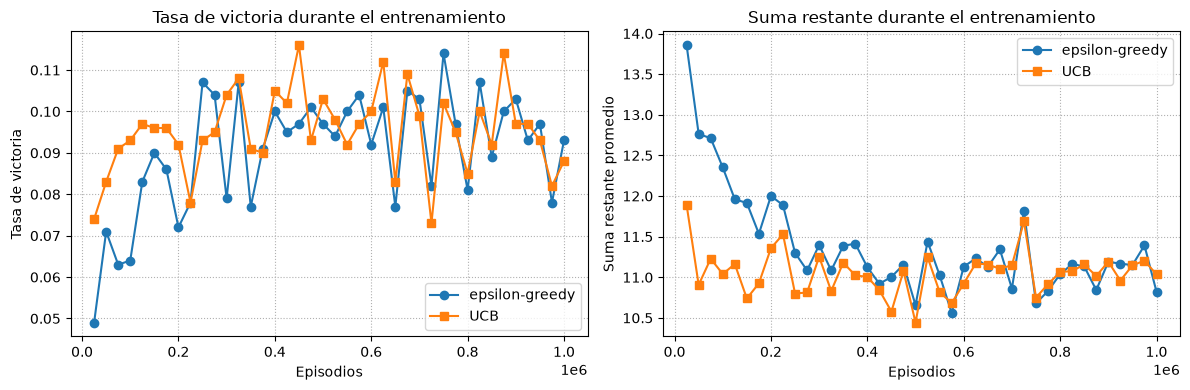

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
episodios_epsilon = [h["episodio"] for h in historial_epsilon]
victorias_epsilon = [h["tasa_victoria"] for h in historial_epsilon]
restante_epsilon = [h["restante_promedio"] for h in historial_epsilon]
episodios_ucb = [h["episodio"] for h in historial_ucb]
victorias_ucb = [h["tasa_victoria"] for h in historial_ucb]
restante_ucb = [h["restante_promedio"] for h in historial_ucb]

ejes[0].plot(episodios_epsilon, victorias_epsilon, marker="o", label="epsilon-greedy")
ejes[0].plot(episodios_ucb, victorias_ucb, marker="s", label="UCB")
ejes[0].set_xlabel("Episodios")
ejes[0].set_ylabel("Tasa de victoria")
ejes[0].set_title("Tasa de victoria durante el entrenamiento")
ejes[0].grid(True, linestyle=":")
ejes[0].legend()

ejes[1].plot(episodios_epsilon, restante_epsilon, marker="o", label="epsilon-greedy")
ejes[1].plot(episodios_ucb, restante_ucb, marker="s", label="UCB")
ejes[1].set_xlabel("Episodios")
ejes[1].set_ylabel("Suma restante promedio")
ejes[1].set_title("Suma restante durante el entrenamiento")
ejes[1].grid(True, linestyle=":")
ejes[1].legend()

plt.tight_layout()
plt.show()

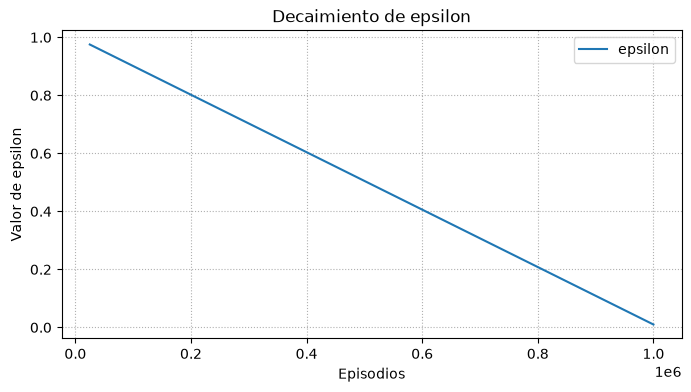

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(episodios_epsilon, [h["epsilon"] for h in historial_epsilon], label="epsilon")
plt.xlabel("Episodios")
plt.ylabel("Valor de epsilon")
plt.title("Decaimiento de epsilon")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## 7. Evaluación final

Se evalúan las políticas de forma greedy (sin exploración) sobre 10 000
partidas. Se reportan la tasa de victoria, la suma restante promedio y los
pasos promedio. La política aleatoria sirve de línea base.

In [11]:
resultado_aleatorio = evaluar(politica_aleatoria, partidas=10_000, semilla=1001)
resultado_epsilon = evaluar(politica_greedy(Q_epsilon), partidas=10_000, semilla=1001)
resultado_ucb = evaluar(politica_greedy(Q_ucb), partidas=10_000, semilla=1001)

print("Política aleatoria")
print(f"  Tasa de victoria: {resultado_aleatorio['tasa_victoria']:.4f}")
print(f"  Suma restante promedio: {resultado_aleatorio['restante_promedio']:.4f}")
print(f"  Pasos promedio: {resultado_aleatorio['pasos_promedio']:.2f}")
print()
print("Agente epsilon-greedy")
print(f"  Tasa de victoria: {resultado_epsilon['tasa_victoria']:.4f}")
print(f"  Suma restante promedio: {resultado_epsilon['restante_promedio']:.4f}")
print(f"  Pasos promedio: {resultado_epsilon['pasos_promedio']:.2f}")
print()
print("Agente UCB")
print(f"  Tasa de victoria: {resultado_ucb['tasa_victoria']:.4f}")
print(f"  Suma restante promedio: {resultado_ucb['restante_promedio']:.4f}")
print(f"  Pasos promedio: {resultado_ucb['pasos_promedio']:.2f}")

Política aleatoria
  Tasa de victoria: 0.0204
  Suma restante promedio: 20.4121
  Pasos promedio: 7.79

Agente epsilon-greedy
  Tasa de victoria: 0.0968
  Suma restante promedio: 11.1182
  Pasos promedio: 10.61

Agente UCB
  Tasa de victoria: 0.0940
  Suma restante promedio: 11.1339
  Pasos promedio: 10.61


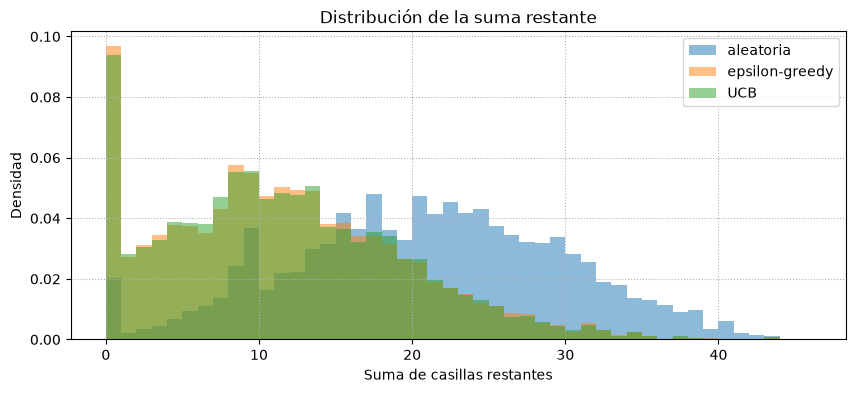

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(resultado_aleatorio["restantes"], bins=range(0, 47), alpha=0.5, label="aleatoria", density=True)
plt.hist(resultado_epsilon["restantes"], bins=range(0, 47), alpha=0.5, label="epsilon-greedy", density=True)
plt.hist(resultado_ucb["restantes"], bins=range(0, 47), alpha=0.5, label="UCB", density=True)
plt.xlabel("Suma de casillas restantes")
plt.ylabel("Densidad")
plt.title("Distribución de la suma restante")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## 8. Política aprendida

En el estado inicial solo se pueden tirar dos dados porque 7, 8 y 9 están abiertos.
Cuando esas tres casillas se cierran, el agente también aprende si conviene tirar
uno o dos dados. Los valores `Q` mostrados estiman el retorno esperado con la
recompensa densa, no la probabilidad de victoria.

In [13]:
def numeros_de_accion(accion):
    return [n for n in NUMEROS if accion & (1 << (n - 1))]


def mostrar_politica(Q, mascara):
    print(f"Máscara {mascara:09b} | casillas abiertas: {abiertas(mascara)}")
    if (mascara & MASCARA_789) == 0:
        valores = [Q.get(((mascara, 0), a), 0.0) for a in (1, 2)]
        mejor = (1, 2)[int(np.argmax(valores))]
        print(f"  Dados: tirar {mejor} (Q: 1={valores[0]:.3f}, 2={valores[1]:.3f})")
        totales = range(1, 13)
    else:
        print("  Dados: solo se puede tirar 2")
        totales = range(2, 13)
    for total in totales:
        validas = acciones_validas(mascara, total)
        if not validas:
            continue
        valores = [Q.get(((mascara, total), a), 0.0) for a in validas]
        mejor = validas[int(np.argmax(valores))]
        print(f"  Total {total:2d}: cerrar {numeros_de_accion(mejor)} (Q={max(valores):.3f})")
    print()


mostrar_politica(Q_epsilon, MASCARA_COMPLETA)
mostrar_politica(Q_epsilon, MASCARA_COMPLETA & ~MASCARA_789)

Máscara 111111111 | casillas abiertas: [1, 2, 3, 4, 5, 6, 7, 8, 9]
  Dados: solo se puede tirar 2
  Total  2: cerrar [2] (Q=2.913)
  Total  3: cerrar [3] (Q=3.093)
  Total  4: cerrar [4] (Q=3.146)
  Total  5: cerrar [5] (Q=3.311)
  Total  6: cerrar [6] (Q=3.400)
  Total  7: cerrar [7] (Q=3.515)
  Total  8: cerrar [8] (Q=3.712)
  Total  9: cerrar [9] (Q=3.933)
  Total 10: cerrar [1, 9] (Q=3.651)
  Total 11: cerrar [2, 9] (Q=3.633)
  Total 12: cerrar [3, 9] (Q=3.764)

Máscara 000111111 | casillas abiertas: [1, 2, 3, 4, 5, 6]
  Dados: tirar 2 (Q: 1=4.436, 2=4.655)
  Total  1: cerrar [1] (Q=4.384)
  Total  2: cerrar [2] (Q=4.264)
  Total  3: cerrar [3] (Q=4.502)
  Total  4: cerrar [4] (Q=4.673)
  Total  5: cerrar [5] (Q=4.707)
  Total  6: cerrar [6] (Q=4.769)
  Total  7: cerrar [1, 6] (Q=4.646)
  Total  8: cerrar [3, 5] (Q=4.774)
  Total  9: cerrar [3, 6] (Q=4.802)
  Total 10: cerrar [4, 6] (Q=4.853)
  Total 11: cerrar [5, 6] (Q=4.945)
  Total 12: cerrar [3, 4, 5] (Q=4.781)



## 9. Guardar y cargar el agente

La tabla de valores se guarda con `pickle`, igual que la función de valor del
cuadernillo de tres en raya.

In [14]:
RUTA_AGENTE = Path("agente_shut_the_box.pickle")

with open(RUTA_AGENTE, "wb") as archivo:
    pickle.dump({"Q": Q_epsilon, "N": N_epsilon}, archivo)

with open(RUTA_AGENTE, "rb") as archivo:
    agente_cargado = pickle.load(archivo)

Q_cargado = agente_cargado["Q"]
print(f"Pares estado-acción guardados: {len(Q_cargado)}")

Pares estado-acción guardados: 7674


## 10. Juego por consola

`jugar_agente` ejecuta una partida automática. `jugar_humano` permite jugar
manualmente y, opcionalmente, recibir una sugerencia del agente.

In [15]:
def jugar_agente(politica, semilla=67, verbose=True):
    rng = np.random.default_rng(semilla)
    env = ShutTheBox(rng)
    estado = env.reset()
    retorno = 0.0
    done = False
    if verbose:
        print("Inicio:")
        dibujar_tablero(env.mask)
    while not done:
        validas = env.acciones()
        if not validas:
            break
        accion = politica(estado, validas, rng)
        if env.total == 0:
            if verbose:
                print(f"El agente tira {accion} dado(s).")
        else:
            if verbose:
                print(f"Salió {env.total}. El agente cierra {numeros_de_accion(accion)}.")
        estado, recompensa, done, _ = env.step(accion)
        retorno += recompensa
        if verbose:
            dibujar_tablero(env.mask)
    restante = suma_restante(env.mask)
    if verbose:
        if restante == 0:
            print("¡Victoria! Se cerraron todas las casillas.")
        else:
            print(f"Bloqueado. Suma restante: {restante}.")
    return retorno, restante


def jugar_humano(politica=None):
    rng = np.random.default_rng()
    env = ShutTheBox(rng)
    estado = env.reset()
    retorno = 0.0
    done = False
    print("Shut the Box - modo humano")
    dibujar_tablero(env.mask)
    while not done:
        validas = env.acciones()
        if not validas:
            break
        if env.total == 0:
            opciones = acciones_pre_tirada(env.mask)
            if len(opciones) == 1:
                accion = opciones[0]
                print(f"Solo puedes tirar {accion} dado(s).")
            else:
                while True:
                    texto = input("¿Tirar 1 o 2 dados? ").strip()
                    if texto in {"1", "2"} and int(texto) in opciones:
                        accion = int(texto)
                        break
                    print("Opción inválida.")
        else:
            print(f"Salió {env.total}. Combinaciones válidas:")
            for i, sub in enumerate(validas, 1):
                print(f"  {i}: {numeros_de_accion(sub)}")
            if politica is not None:
                sugerencia = politica(estado, validas, rng)
                print(f"Sugerencia del agente: {numeros_de_accion(sugerencia)}")
            while True:
                texto = input("Elige el número de opción: ").strip()
                if texto.isdigit() and 1 <= int(texto) <= len(validas):
                    accion = validas[int(texto) - 1]
                    break
                print("Opción inválida.")
        estado, recompensa, done, _ = env.step(accion)
        retorno += recompensa
        dibujar_tablero(env.mask)
    restante = suma_restante(env.mask)
    if restante == 0:
        print("¡Victoria! Se cerraron todas las casillas.")
    else:
        print(f"Bloqueado. Suma restante: {restante}.")
    return retorno, restante


def comparar_humano_vs_agente(politica, n=1):
    print("Partidas del agente:")
    resultados_agente = [jugar_agente(politica, semilla=2000 + i, verbose=False) for i in range(n)]
    print("Tus partidas:")
    resultados_humano = [jugar_humano(politica) for _ in range(n)]
    victorias_agente = sum(1 for _, s in resultados_agente if s == 0)
    victorias_humano = sum(1 for _, s in resultados_humano if s == 0)
    restante_agente = np.mean([s for _, s in resultados_agente])
    restante_humano = np.mean([s for _, s in resultados_humano])
    print(f"Victorias agente: {victorias_agente}/{n} | suma restante promedio: {restante_agente:.2f}")
    print(f"Victorias humano: {victorias_humano}/{n} | suma restante promedio: {restante_humano:.2f}")

In [16]:
politica_agente = politica_greedy(Q_epsilon)
jugar_agente(politica_agente, semilla=68, verbose=True)

Inicio:
[1] [2] [3] [4] [5] [6] [7] [8] [9]
El agente tira 2 dado(s).
[1] [2] [3] [4] [5] [6] [7] [8] [9]
Salió 7. El agente cierra [7].
[1] [2] [3] [4] [5] [6]  X  [8] [9]
El agente tira 2 dado(s).
[1] [2] [3] [4] [5] [6]  X  [8] [9]
Salió 10. El agente cierra [1, 9].
 X  [2] [3] [4] [5] [6]  X  [8]  X 
El agente tira 2 dado(s).
 X  [2] [3] [4] [5] [6]  X  [8]  X 
Salió 8. El agente cierra [8].
 X  [2] [3] [4] [5] [6]  X   X   X 
El agente tira 2 dado(s).
 X  [2] [3] [4] [5] [6]  X   X   X 
Salió 8. El agente cierra [2, 6].
 X   X  [3] [4] [5]  X   X   X   X 
El agente tira 2 dado(s).
 X   X  [3] [4] [5]  X   X   X   X 
Salió 12. El agente cierra [3, 4, 5].
 X   X   X   X   X   X   X   X   X 
¡Victoria! Se cerraron todas las casillas.


(6.0, 0)

Para jugar manualmente, ejecuta `jugar_humano(politica_agente)` en una celda.
Para comparar, ejecuta `comparar_humano_vs_agente(politica_agente, n=1)`.

## 11. Conclusiones

El agente aprende por prueba y error, sin conocer las probabilidades de los dados.
La tabla `Q` estima el retorno esperado (casillas cerradas normalizadas más el
bonus por victoria). La comparación con la política aleatoria muestra una mejora
clara: se pasa de aproximadamente 2% a más de 9% de victorias, acercándose al
óptimo teórico de estas reglas (alrededor de 9.8%). Las curvas permiten ver el
efecto de ε y de UCB. La recompensa densa fue clave: con solo `+1` al ganar, el
agente apenas superaba el 3% de victorias con el mismo presupuesto de episodios.

In [17]:
print("Resumen final")
print(f"Aleatoria      -> victoria: {resultado_aleatorio['tasa_victoria']:.3f} | restante: {resultado_aleatorio['restante_promedio']:.2f}")
print(f"epsilon-greedy -> victoria: {resultado_epsilon['tasa_victoria']:.3f} | restante: {resultado_epsilon['restante_promedio']:.2f}")
print(f"UCB            -> victoria: {resultado_ucb['tasa_victoria']:.3f} | restante: {resultado_ucb['restante_promedio']:.2f}")

Resumen final
Aleatoria      -> victoria: 0.020 | restante: 20.41
epsilon-greedy -> victoria: 0.097 | restante: 11.12
UCB            -> victoria: 0.094 | restante: 11.13
